# 02 - Supervised models

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, train_val_split, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import (
    evaluate_binary, choose_threshold, evaluate_multiclass, evaluate_test,
    save_result, plot_roc_pr, plot_confusion,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
Xm_tr, Xm_val, ym_tr, ym_val = train_val_split(train_df, "attack_cat")

len(X_tr), len(X_val), len(Xm_tr), len(Xm_val), len(X_test), int(unseen.sum())

(80752, 20189, 80341, 20086, 82332, 73791)

Binary: the threshold is picked on validation with an FPR budget of 1% and then used as is on test.
Every test result is reported on the full test set and on the unseen rows.

In [4]:
MAX_FPR = 0.01

## Dummy baseline

Predicts the class priors seen in train, the same score for every flow. Used to check the whole flow end to end,
and as the floor any real model has to beat.

In [5]:
dummy = make_pipeline(build_preprocessor(), DummyClassifier(strategy="prior"))
dummy.fit(X_tr, y_tr)

scores_val = dummy.predict_proba(X_val)[:, 1]
scores_test = dummy.predict_proba(X_test)[:, 1]
threshold = choose_threshold(y_val, scores_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, scores_val, threshold, categories=train_df.loc[X_val.index, "attack_cat"]),
    **evaluate_test(evaluate_binary, y_test, scores_test, unseen, categories=y_test_multi, threshold=threshold),
}
save_result("Dummy (prior)", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR})

{k: {m: v[m] for m in ["recall", "fpr", "roc_auc", "pr_auc"]} for k, v in metrics.items()}

{'val': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.4877408489771658},
 'test': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5506000097167566},
 'test_unseen': {'recall': 0.0,
  'fpr': 0.0,
  'roc_auc': 0.5,
  'pr_auc': 0.5185320703066769}}

Same scores with the max-F1 threshold: flags every flow.

In [6]:
t_f1 = choose_threshold(y_val, scores_val, "f1")
m = evaluate_binary(y_test, scores_test, t_f1)
m["recall"], m["fpr"], m["precision"]

(1.0, 1.0, 0.5506000097167566)

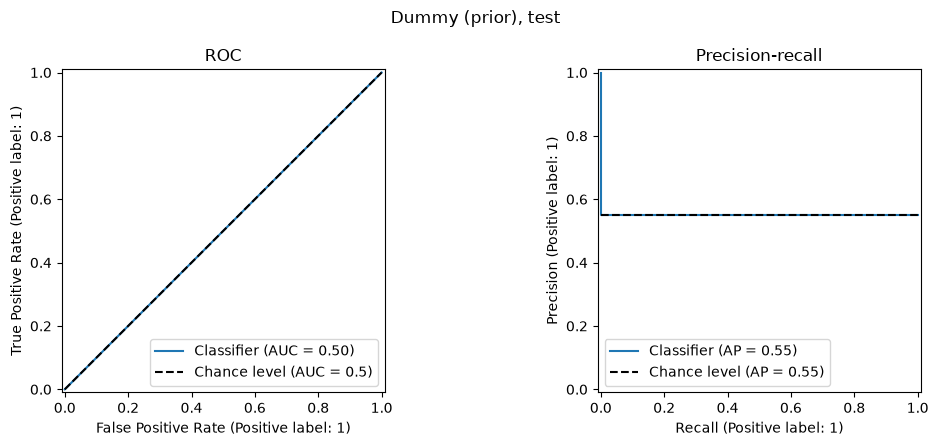

In [7]:
fig = plot_roc_pr(y_test, scores_test, "Dummy (prior), test")
plt.show()

In [8]:
dummy_multi = make_pipeline(build_preprocessor(), DummyClassifier(strategy="most_frequent"))
dummy_multi.fit(Xm_tr, ym_tr)

labels = sorted(ym_tr.unique())
metrics = {
    "val": evaluate_multiclass(ym_val, dummy_multi.predict(Xm_val), labels),
    **evaluate_test(evaluate_multiclass, y_test_multi, dummy_multi.predict(X_test), unseen, labels=labels),
}
save_result("Dummy (most frequent)", "multiclass", metrics)

{k: {m: v[m] for m in ["accuracy", "macro_f1"]} for k, v in metrics.items()}

{'val': {'accuracy': 0.5148859902419596, 'macro_f1': 0.0679768634152754},
 'test': {'accuracy': 0.44939999028324346, 'macro_f1': 0.06201186605436933},
 'test_unseen': {'accuracy': 0.481467929693323,
  'macro_f1': 0.0649987650820077}}

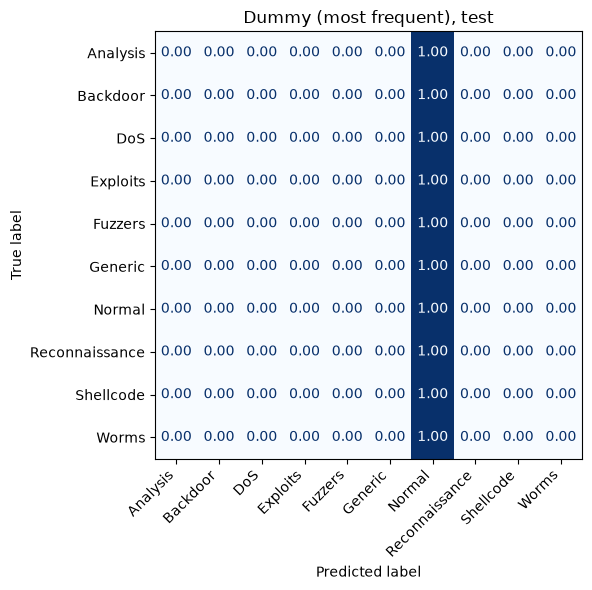

In [9]:
fig = plot_confusion(metrics["test"]["confusion_matrix"], labels, "Dummy (most frequent), test")
plt.show()

## Supervised models

Three models, each in `make_pipeline(build_preprocessor(), model)`: logistic regression (linear baseline), random forest and histogram gradient boosting.

- Hyperparameters: `RandomizedSearchCV` with 3-fold stratified CV on the training part only (one row per feature vector, so folds don't share flows).
- Binary search metric: ROC-AUC restricted to FPR <= 1% (standardized, 0.5 = random, 1 = perfect), since that is the region where the alert threshold will sit. Multi-class: macro-F1.
- Validation is used to pick the threshold and to compare models. The test set is only used once, in the "Test" section.

In [10]:
import pandas as pd
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, roc_auc_score
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from netad.evaluation import FIGURES_DIR
from netad.preprocessing import TTL_COLUMNS

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
pauc = make_scorer(roc_auc_score, response_method="predict_proba", max_fpr=MAX_FPR)


def tune(model, space, X, y, scoring, n_iter=12):
    search = RandomizedSearchCV(
        make_pipeline(build_preprocessor(), model), space,
        n_iter=n_iter, scoring=scoring, cv=cv, n_jobs=-1, random_state=42,
    )
    return search.fit(X, y)


def clean(params):
    """best_params_ without the pipeline prefix and numpy types, for results.json"""
    return {k.split("__")[-1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

### Binary: tuning

In [11]:
binary_space = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000),
        {"logisticregression__C": loguniform(1e-3, 1e2)},
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42),
        {
            "randomforestclassifier__n_estimators": [200, 400],
            "randomforestclassifier__max_depth": [None, 20, 30],
            "randomforestclassifier__min_samples_leaf": [1, 2, 5],
            "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5],
        },
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=42),
        {
            "histgradientboostingclassifier__learning_rate": loguniform(0.03, 0.3),
            "histgradientboostingclassifier__max_iter": [200, 400],
            "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
            "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
            "histgradientboostingclassifier__l2_regularization": loguniform(1e-4, 1),
        },
    ),
}

binary_search = {}
for name, (model, space) in binary_space.items():
    binary_search[name] = tune(model, space, X_tr, y_tr, pauc)
    print(f"{name}: cv pAUC {binary_search[name].best_score_:.4f}", clean(binary_search[name].best_params_))

LogisticRegression: cv pAUC 0.7058 {'C': 70.72114131472235}


RandomForest: cv pAUC 0.8187 {'n_estimators': 400, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20}


HistGradientBoosting: cv pAUC 0.8204 {'l2_regularization': 0.001653693718282443, 'learning_rate': 0.037565862861181167, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 100}


### Binary: validation

In [12]:
val_categories = train_df.loc[X_val.index, "attack_cat"]

binary = {}
for name, search in binary_search.items():
    model = search.best_estimator_
    s_val = model.predict_proba(X_val)[:, 1]
    threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)
    binary[name] = {
        "model": model,
        "params": clean(search.best_params_),
        "threshold": threshold,
        "val_pauc": roc_auc_score(y_val, s_val, max_fpr=MAX_FPR),
        "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    }

pd.DataFrame({
    name: {
        "cv pAUC": binary_search[name].best_score_,
        "val pAUC": b["val_pauc"],
        "val ROC-AUC": b["val"]["roc_auc"],
        "val recall": b["val"]["recall"],
        "val FPR": b["val"]["fpr"],
        "val precision": b["val"]["precision"],
    }
    for name, b in binary.items()
}).T.round(4)

,cv pAUC,val pAUC,val ROC-AUC,val recall,val FPR,val precision
LogisticRegression,0.7058,0.6961,0.9717,0.5406,0.01,0.9810
RandomForest,0.8187,0.8237,0.9853,0.7443,0.01,0.9861
HistGradientBoosting,0.8204,0.8210,0.9855,0.7559,0.01,0.9864


In [13]:
best_binary = max(binary, key=lambda name: binary[name]["val_pauc"])
best_binary

'RandomForest'

### Multi-class: tuning

`class_weight` is part of the search, so `"balanced"` is kept only if it helps macro-F1 in CV.

In [14]:
multi_space = {
    "LogisticRegression": (
        LogisticRegression(max_iter=2000),
        {
            "logisticregression__C": loguniform(1e-3, 1e2),
            "logisticregression__class_weight": [None, "balanced"],
        },
    ),
    "RandomForest": (
        RandomForestClassifier(random_state=42),
        {
            "randomforestclassifier__n_estimators": [200, 400],
            "randomforestclassifier__max_depth": [None, 20, 30],
            "randomforestclassifier__min_samples_leaf": [1, 2, 5],
            "randomforestclassifier__max_features": ["sqrt", 0.3, 0.5],
            "randomforestclassifier__class_weight": [None, "balanced", "balanced_subsample"],
        },
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=42),
        {
            "histgradientboostingclassifier__learning_rate": loguniform(0.03, 0.3),
            "histgradientboostingclassifier__max_iter": [200, 400],
            "histgradientboostingclassifier__max_leaf_nodes": [15, 31, 63],
            "histgradientboostingclassifier__min_samples_leaf": [20, 50, 100],
            "histgradientboostingclassifier__l2_regularization": loguniform(1e-4, 1),
            "histgradientboostingclassifier__class_weight": [None, "balanced"],
        },
    ),
}

multi_search = {}
for name, (model, space) in multi_space.items():
    multi_search[name] = tune(model, space, Xm_tr, ym_tr, "f1_macro")
    print(f"{name}: cv macro-F1 {multi_search[name].best_score_:.4f}", clean(multi_search[name].best_params_))

LogisticRegression: cv macro-F1 0.5003 {'C': 1.1435780278433403, 'class_weight': None}


RandomForest: cv macro-F1 0.7263 {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 30, 'class_weight': 'balanced_subsample'}


HistGradientBoosting: cv macro-F1 0.7025 {'class_weight': 'balanced', 'l2_regularization': 0.00023036990230378664, 'learning_rate': 0.12459690772993168, 'max_iter': 400, 'max_leaf_nodes': 63, 'min_samples_leaf': 20}


### Multi-class: validation

In [15]:
multi = {}
for name, search in multi_search.items():
    model = search.best_estimator_
    multi[name] = {
        "model": model,
        "params": clean(search.best_params_),
        "val": evaluate_multiclass(ym_val, model.predict(Xm_val), labels),
    }

pd.DataFrame({
    name: {
        "cv macro-F1": multi_search[name].best_score_,
        "val macro-F1": m["val"]["macro_f1"],
        "val accuracy": m["val"]["accuracy"],
        "class_weight": m["params"].get("class_weight"),
    }
    for name, m in multi.items()
}).T

,cv macro-F1,val macro-F1,val accuracy,class_weight
LogisticRegression,0.500267,0.508881,0.808125,NaN
RandomForest,0.726349,0.753643,0.876133,balanced_subsample
HistGradientBoosting,0.702464,0.711695,0.834263,balanced


In [16]:
best_multi = max(multi, key=lambda name: multi[name]["val"]["macro_f1"])
best_multi

'RandomForest'

## Test

Every model is evaluated once on the full test set and on the unseen rows, then saved to `results.json`.

In [17]:
for name, b in binary.items():
    s_test = b["model"].predict_proba(X_test)[:, 1]
    b["scores_test"] = s_test
    b.update(evaluate_test(evaluate_binary, y_test, s_test, unseen, categories=y_test_multi, threshold=b["threshold"]))
    save_result(name, "binary", {"val": b["val"], "test": b["test"], "test_unseen": b["test_unseen"]},
                {"threshold_mode": "fpr", "max_fpr": MAX_FPR, **b["params"]})

pd.DataFrame({
    (name, subset): {m: b[subset][m] for m in ["recall", "fpr", "precision", "f1", "roc_auc", "pr_auc"]}
    for name, b in binary.items()
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

recall     fpr  precision      f1  roc_auc  \
LogisticRegression   val          0.5406  0.0100     0.9810  0.6970   0.9717   
                     test         0.7961  0.0232     0.9767  0.8772   0.9667   
                     test_unseen  0.7622  0.0214     0.9746  0.8554   0.9621   
RandomForest         val          0.7443  0.0100     0.9861  0.8483   0.9853   
                     test         0.8900  0.0395     0.9650  0.9260   0.9818   
                     test_unseen  0.8704  0.0372     0.9618  0.9138   0.9793   
HistGradientBoosting val          0.7559  0.0100     0.9864  0.8559   0.9855   
                     test         0.9151  0.0502     0.9572  0.9357   0.9845   
                     test_unseen  0.9010  0.0494     0.9515  0.9256   0.9823   

                                  pr_auc  
LogisticRegression   val          0.9659  
                     test         0.9732  
                     test_unseen  0.9658  
RandomForest         val          0.9839  
                     test         0.9862  
                     test_unseen  0.9822  
HistGradientBoosting val          0.9840  
                     test         0.9885  
                     test_unseen  0.9851

Detection rate per attack category (share flagged as attack; for Normal this is the FPR):

In [18]:
by_category = pd.DataFrame({
    (name, subset): {cat: v["flagged"] for cat, v in b[subset]["by_category"].items()}
    for name, b in binary.items()
    for subset in ["test", "test_unseen"]
})
by_category.round(3)

LogisticRegression             RandomForest              \
                             test test_unseen         test test_unseen   
Analysis                    0.914       0.895        0.914       0.895   
Backdoor                    0.933       0.933        0.986       0.986   
DoS                         0.868       0.750        0.956       0.915   
Exploits                    0.788       0.747        0.940       0.929   
Fuzzers                     0.272       0.244        0.380       0.356   
Generic                     0.983       0.982        0.993       0.992   
Normal                      0.023       0.021        0.040       0.037   
Reconnaissance              0.625       0.478        0.962       0.944   
Shellcode                   0.500       0.485        0.873       0.868   
Worms                       0.773       0.773        0.932       0.932   

               HistGradientBoosting              
                               test test_unseen  
Analysis                      0.934       0.918  
Backdoor                      0.981       0.981  
DoS                           0.973       0.951  
Exploits                      0.958       0.952  
Fuzzers                       0.495       0.477  
Generic                       0.998       0.998  
Normal                        0.050       0.049  
Reconnaissance                0.981       0.972  
Shellcode                     0.902       0.899  
Worms                         0.977       0.977

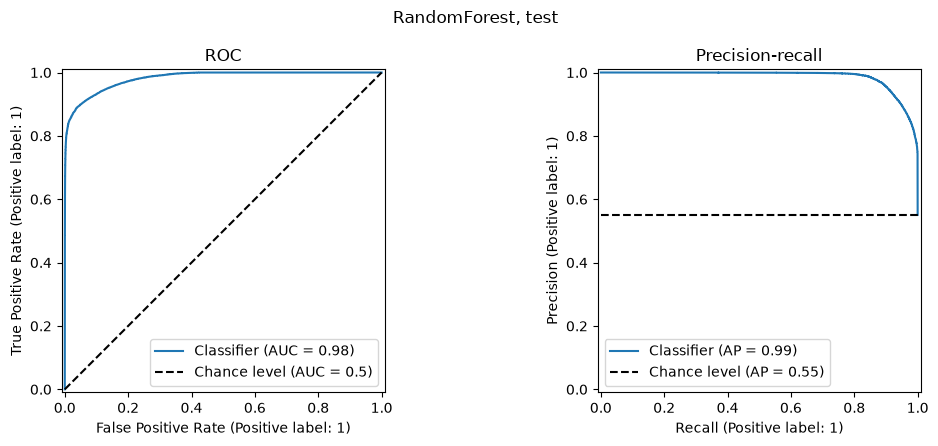

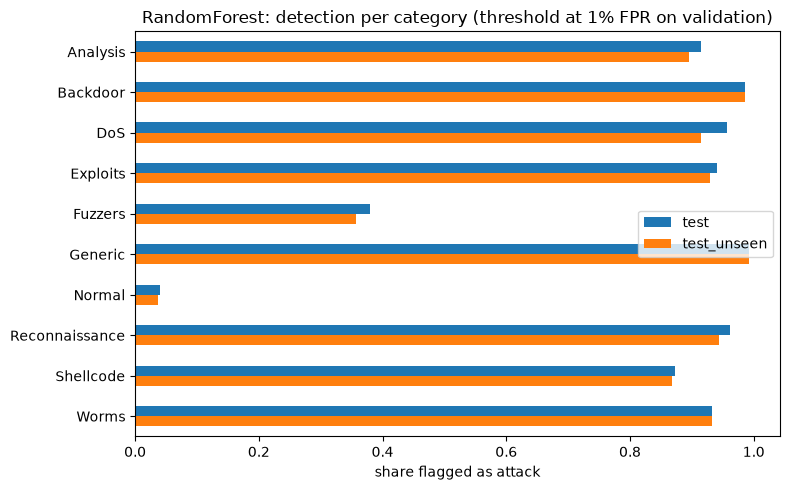

In [19]:
b = binary[best_binary]
fig = plot_roc_pr(y_test, b["scores_test"], f"{best_binary}, test", path=FIGURES_DIR / "binary_roc_pr.png")
plt.show()

ax = by_category[best_binary].plot.barh(figsize=(8, 5))
ax.invert_yaxis()
ax.set_xlabel("share flagged as attack")
ax.set_title(f"{best_binary}: detection per category (threshold at 1% FPR on validation)")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "binary_detection_by_category.png", dpi=120)
plt.show()

In [20]:
for name, m in multi.items():
    m.update(evaluate_test(evaluate_multiclass, y_test_multi, m["model"].predict(X_test), unseen, labels=labels))
    save_result(name, "multiclass", {"val": m["val"], "test": m["test"], "test_unseen": m["test_unseen"]}, m["params"])

pd.DataFrame({
    (name, subset): {k: m[subset][k] for k in ["accuracy", "macro_f1", "weighted_f1"]}
    for name, m in multi.items()
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

accuracy  macro_f1  weighted_f1
LogisticRegression   val            0.8081    0.5089       0.7997
                     test           0.7253    0.3911       0.7296
                     test_unseen    0.7380    0.3894       0.7507
RandomForest         val            0.8761    0.7536       0.8780
                     test           0.7316    0.5174       0.7582
                     test_unseen    0.7545    0.5417       0.7786
HistGradientBoosting val            0.8343    0.7117       0.8451
                     test           0.6884    0.4948       0.7293
                     test_unseen    0.7089    0.5127       0.7453

In [21]:
pd.DataFrame({
    name: {cls: v["f1"] for cls, v in m["test"]["per_class"].items()}
    for name, m in multi.items()
}).round(3)

,LogisticRegression,RandomForest,HistGradientBoosting
Analysis,0.000,0.000,0.000
Backdoor,0.082,0.032,0.029
DoS,0.015,0.261,0.311
Exploits,0.661,0.701,0.657
Fuzzers,0.366,0.363,0.359
Generic,0.980,0.985,0.984
Normal,0.799,0.798,0.745
Reconnaissance,0.635,0.864,0.857
Shellcode,0.293,0.438,0.341
Worms,0.080,0.731,0.667


Ceiling: on test, a predictor that knows the test labels and answers with the most frequent class of each feature vector (ties broken arbitrarily).
No model can do better on these rows, see 01_eda.

In [22]:
counts = test_df.groupby(FEATURES + ["attack_cat"]).size().rename("n").reset_index()
majority = counts.sort_values("n", ascending=False).drop_duplicates(FEATURES)[FEATURES + ["attack_cat"]]
oracle = test_df[FEATURES].merge(majority, on=FEATURES, how="left")["attack_cat"]
ceiling = evaluate_multiclass(y_test_multi, oracle, labels)

pd.DataFrame({
    "ceiling": {"accuracy": ceiling["accuracy"], "macro_f1": ceiling["macro_f1"]},
    best_multi: {"accuracy": multi[best_multi]["test"]["accuracy"], "macro_f1": multi[best_multi]["test"]["macro_f1"]},
}).round(4)

,ceiling,RandomForest
accuracy,0.9360,0.7316
macro_f1,0.7634,0.5174


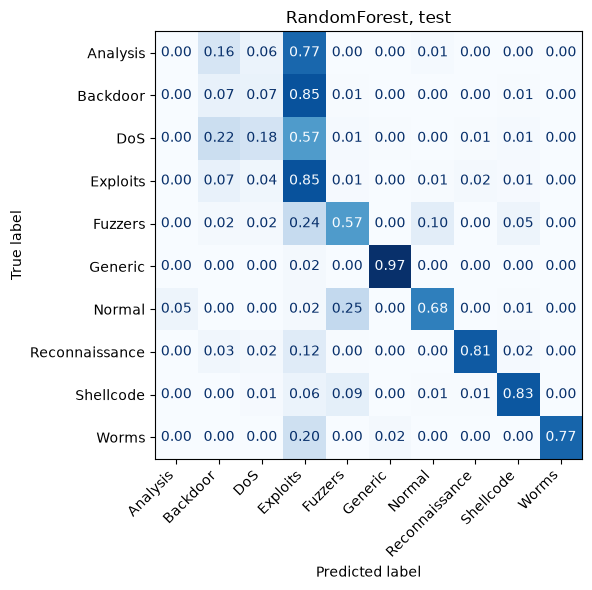

In [23]:
fig = plot_confusion(multi[best_multi]["test"]["confusion_matrix"], labels, f"{best_multi}, test",
                     path=FIGURES_DIR / "multiclass_confusion.png")
plt.show()

## TTL ablation

Best model of each task retrained with the same hyperparameters, without `sttl`, `dttl`, `ct_state_ttl`.
If performance drops a lot, the model leans on how the testbed was wired rather than on how the attacks behave.

In [24]:
def without_ttl(model, X, y):
    return make_pipeline(build_preprocessor(exclude=TTL_COLUMNS), clone(model[-1])).fit(X, y)


b = binary[best_binary]
no_ttl = without_ttl(b["model"], X_tr, y_tr)
s_val = no_ttl.predict_proba(X_val)[:, 1]
threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)
ablation_binary = {
    "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, no_ttl.predict_proba(X_test)[:, 1], unseen,
                    categories=y_test_multi, threshold=threshold),
}
save_result(f"{best_binary} (no TTL)", "binary", ablation_binary,
            {"threshold_mode": "fpr", "max_fpr": MAX_FPR, "excluded": TTL_COLUMNS, **b["params"]})

pd.DataFrame({
    (version, subset): {m: res[subset][m] for m in ["recall", "fpr", "precision", "roc_auc"]}
    for version, res in [("with TTL", b), ("no TTL", ablation_binary)]
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

recall     fpr  precision  roc_auc
with TTL val          0.7443  0.0100     0.9861   0.9853
         test         0.8900  0.0395     0.9650   0.9818
         test_unseen  0.8704  0.0372     0.9618   0.9793
no TTL   val          0.7438  0.0100     0.9861   0.9852
         test         0.8858  0.0430     0.9619   0.9802
         test_unseen  0.8654  0.0401     0.9587   0.9775

In [25]:
pd.DataFrame({
    ("with TTL", "test_unseen"): {c: v["flagged"] for c, v in b["test_unseen"]["by_category"].items()},
    ("no TTL", "test_unseen"): {c: v["flagged"] for c, v in ablation_binary["test_unseen"]["by_category"].items()},
}).round(3)

,with TTL,no TTL
,test_unseen,test_unseen
Analysis,0.895,0.893
Backdoor,0.986,0.981
DoS,0.915,0.897
Exploits,0.929,0.920
Fuzzers,0.356,0.353
Generic,0.992,0.989
Normal,0.037,0.040
Reconnaissance,0.944,0.942
Shellcode,0.868,0.866


In [26]:
m = multi[best_multi]
no_ttl_multi = without_ttl(m["model"], Xm_tr, ym_tr)
ablation_multi = {
    "val": evaluate_multiclass(ym_val, no_ttl_multi.predict(Xm_val), labels),
    **evaluate_test(evaluate_multiclass, y_test_multi, no_ttl_multi.predict(X_test), unseen, labels=labels),
}
save_result(f"{best_multi} (no TTL)", "multiclass", ablation_multi, {"excluded": TTL_COLUMNS, **m["params"]})

pd.DataFrame({
    (version, subset): {k: res[subset][k] for k in ["accuracy", "macro_f1"]}
    for version, res in [("with TTL", m), ("no TTL", ablation_multi)]
    for subset in ["val", "test", "test_unseen"]
}).T.round(4)

accuracy  macro_f1
with TTL val            0.8761    0.7536
         test           0.7316    0.5174
         test_unseen    0.7545    0.5417
no TTL   val            0.8742    0.7364
         test           0.7285    0.5046
         test_unseen    0.7513    0.5263

## Permutation importance

Best binary model, on validation, with the same partial ROC-AUC score used for tuning. A column's importance is how much the score drops when that column is shuffled.

In [27]:
imp = permutation_importance(binary[best_binary]["model"], X_val, y_val, scoring=pauc,
                             n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"mean": imp["importances_mean"], "std": imp["importances_std"]},
                          index=X_val.columns).sort_values("mean", ascending=False)
importance.head(15).round(4)

,mean,std
dttl,0.1178,0.0038
sttl,0.1165,0.0038
ct_state_ttl,0.0879,0.0051
ackdat,0.0482,0.0031
sbytes,0.0425,0.0040
service,0.0375,0.0022
ct_srv_src,0.0315,0.0026
dbytes,0.0304,0.0031
smean,0.0293,0.0026
ct_srv_dst,0.0289,0.0044


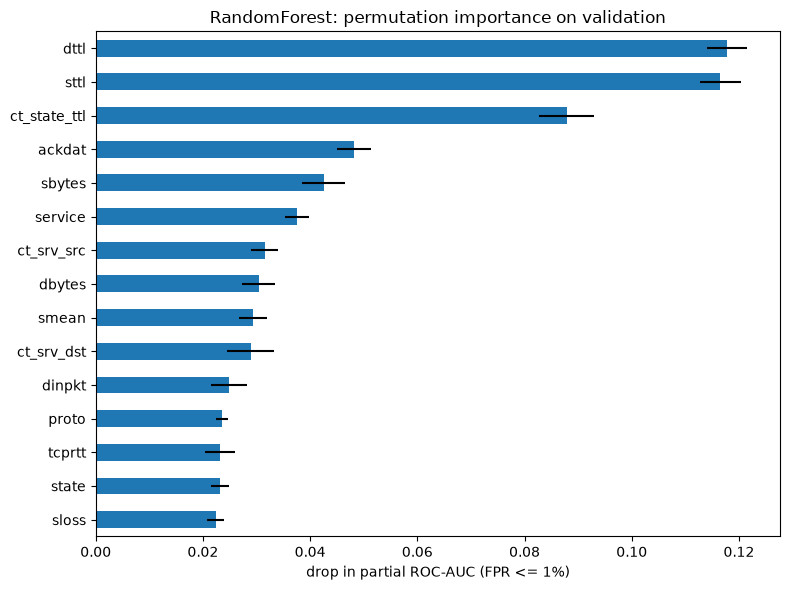

In [28]:
top = importance.head(15)[::-1]
ax = top["mean"].plot.barh(xerr=top["std"], figsize=(8, 6))
ax.set_xlabel("drop in partial ROC-AUC (FPR <= 1%)")
ax.set_title(f"{best_binary}: permutation importance on validation")
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "binary_permutation_importance.png", dpi=120)
plt.show()

## Conclusions

1. **Binary detection works, but the threshold does not transfer.** The threshold was set for 1% FPR on validation. On test the random forest flags 89% of attacks (87% on unseen rows) at 4.0% FPR, gradient boosting 92% at 5.0%. FPR roughly quadruples because normal traffic in the test file is not distributed like normal traffic in train. At 1M normal flows a day that is ~40,000 false alerts instead of the planned 10,000, so in a real deployment the threshold has to be recalibrated on traffic from that network.
2. **Fuzzers is the blind spot.** The random forest flags every other attack category at 87% or more (all above 90% except Shellcode). Fuzzers is caught only 36-50% of the time, and in multi-class 25% of Normal test flows are predicted as Fuzzers: the two overlap at flow level.
3. **Multi-class hits the limits found in the EDA.** Best model: random forest with `class_weight="balanced_subsample"` (balanced weights also won for gradient boosting, not for logistic regression). Macro-F1 is 0.75 on validation but 0.52 on test (0.54 unseen), against a ceiling of 0.76. Analysis, Backdoor and DoS are mostly predicted as Exploits (F1 0.00, 0.03, 0.26). The binary model still flags 91-99% of them as attacks, so they are detected, just not named correctly.
4. **TTL helps, but the models do not depend on it.** The three TTL columns are the top 3 in permutation importance. Retraining without them costs little: test recall 89.0% -> 88.6% with FPR 4.0% -> 4.3% (binary), macro-F1 0.517 -> 0.505 (multi-class). The model uses TTL when it is there, but the same information is mostly available from other columns (`state`, `service`, `ackdat`, byte counts).